# Solar filament segmentation: end-to-end inference

This notebook rebuilds the two final submissions from the 15 U-Net checkpoints in `weights/`, using only
the test H-alpha images. It then walks through every post-processing step on one test image.

| Family | Encoder | Input | Used in |
|---|---|---|---|
| N1 | EfficientNet-B4 | whole image resized to 1024 | final 1, final 2 |
| N9' | EfficientNetV2-S (ImageNet-21k) | trained on 512 crops at native 2048, applied to the full 2048 image | final 1, final 2 |
| N2 | EfficientNet-B4 | trained on 1024 crops at native 2048 | final 1 only |

* **final 2 (main pipeline, described in the report)**: N1 + N9' family maps averaged 1:1 at 2048 →
  hysteresis (p > 0.5, area ≥ 200 px, peak > 0.99) → oriented fragment grouping (disk r 6 ∪ ±16 px line
  along the major axis) → false-positive filter (`configs/fpfilter_ens_n1n9p_orient.pkl`, threshold 0.275).
  Out-of-fold PQ 0.4382, public LB 0.38.
* **final 1**: the same with N2 added (1:1:1) and its own filter (`configs/fpfilter_ens_n1n2n9p_orient.pkl`,
  threshold 0.375). Out-of-fold PQ 0.4372, public LB 0.38.

Every map is the mean of 8 test-time augmentations (4 rotations × flip) and is stored as uint8. A
checkpoint whose map folder under `outputs/final/maps/` already holds all test images is not recomputed
(resume after an interruption, or maps computed on another machine).
Training is not repeated here: see `colab/train_unet.ipynb` and the *Reproduce* section of the README.

Runs on Kaggle (attach the competition data; two T4 GPUs: about 90 min for all 15 models) or locally from
the repository root. Set `FILSEG_FINALS=final2` to compute only the main pipeline (10 models).

In [1]:
# parameters
import os, sys
from pathlib import Path
ON_KAGGLE = os.path.isdir('/kaggle/input')
REPO = Path('/kaggle/working/repo') if ON_KAGGLE else next(d for d in (Path.cwd(), Path.cwd().parent) if (d / 'src' / 'filseg').is_dir())
WEIGHTS = Path(os.environ.get('FILSEG_WEIGHTS', REPO / 'weights'))
OUT = Path('/kaggle/working') if ON_KAGGLE else REPO / 'outputs' / 'final'
N1 = [f'effb4_s1024_f{k}' for k in range(5)]
N2 = [f'effb4_c2048_f{k}' for k in range(5)]
N9 = [f'effv2s_c512_f{k}' for k in range(5)]
FINALS = os.environ.get('FILSEG_FINALS', 'final1,final2').split(',')
FAMILIES = {'n1': N1, 'n9p': N9} | ({'n2': N2} if 'final1' in FINALS else {})
print('finals:', FINALS, '| checkpoints:', sum(len(v) for v in FAMILIES.values()))

finals: ['final1', 'final2'] | checkpoints: 15


## 1. Setup and checks

In [2]:
import glob, subprocess
os.chdir(REPO)
if ON_KAGGLE:
    imgs = glob.glob('/kaggle/input/**/test_images', recursive=True)
    assert imgs, 'attach the competition data'
    data = REPO / 'data'
    data.mkdir(exist_ok=True)
    link = data / 'MAGFiLO_1.0_Kaggle_2026'
    if not link.exists():
        link.mkdir()
        (link / 'test').mkdir()
        (link / 'test' / 'test_images').symlink_to(imgs[0])
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'segmentation-models-pytorch==0.5.0'], check=True)
sys.path.insert(0, str(REPO / 'src'))
import torch, segmentation_models_pytorch as smp
print('torch', torch.__version__, 'smp', smp.__version__, 'gpus', torch.cuda.device_count())
missing = [n for f in FAMILIES.values() for n in f if not (WEIGHTS / f'{n}.pt').exists()]
assert not missing, f'missing checkpoints in {WEIGHTS}: {missing}'
# checkpoint integrity against weights/SHA256SUMS
import hashlib
sums = dict(l.split()[::-1] for l in (REPO / 'weights' / 'SHA256SUMS').read_text().splitlines() if l.strip())
bad = [n for f in FAMILIES.values() for n in f
       if hashlib.sha256((WEIGHTS / f'{n}.pt').read_bytes()).hexdigest() != sums[f'{n}.pt']]
assert not bad, f'checksum mismatch: {bad}'
print('checkpoints verified')

<venv>/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1 smp 0.5.0 gpus 0


checkpoints verified


## 2. Probability maps

`scripts/infer_probs.py` runs one checkpoint with 8x TTA on every test image and saves one uint8 map per
image. On a 2-GPU machine N2 runs on the second GPU in parallel.

In [3]:
# 8x-TTA test maps per checkpoint; N1 + N9' on GPU 0, N2 on GPU 1 when there are two
import time
t0 = time.time()
ngpu = max(torch.cuda.device_count(), 1)
def chain(names, gpu):
    cmds = [f'{sys.executable} scripts/infer_probs.py --ckpt {WEIGHTS}/{n}.pt --which test --tta '
            f'--out {OUT}/maps/{n}' for n in names]
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu % ngpu))
    return subprocess.Popen(' && '.join(cmds), shell=True, env=env)
# a checkpoint whose map folder already holds every test image is reused (resume, or maps made elsewhere)
from filseg.data import test_paths
n_test = len(test_paths())
stems = {p.stem for p in test_paths()}
# compare names, not counts: ignores AppleDouble '._x.npy' files left by exFAT drives
done = lambda n: stems <= {p.stem for p in (OUT / 'maps' / n).glob('*.npy')}
groups = [[n for n in g if not done(n)] for g in [N1 + N9] + ([N2] if 'n2' in FAMILIES else [])]
print(f'{n_test} test images; computing {sum(map(len, groups))} checkpoints, reusing '
      f'{sum(len(f) for f in FAMILIES.values()) - sum(map(len, groups))}')
groups = [g for g in groups if g]
procs = [chain(g, i) for i, g in enumerate(groups)] if ngpu > 1 else [chain(sum(groups, []), 0)] if groups else []
assert all(p.wait() == 0 for p in procs), 'inference failed'
t_maps = time.time() - t0
print(f'maps done in {t_maps / 60:.1f} min')

180 test images; computing 0 checkpoints, reusing 15
maps done in 0.0 min


## 3. Family and pool maps, then the submissions

Fold models of one family are averaged, then families are averaged with equal weight (N1 maps are
upsampled from 1024 to 2048). `scripts/make_submission.py` applies the post-processing stored in the
filter file, the filter itself, and writes COCO RLE.

In [4]:
def run(cmd):
    print('>>', cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True)
t0 = time.time()
m = OUT / 'maps'
for fam, names in FAMILIES.items():
    run(f'{sys.executable} scripts/ensemble_probs.py --inputs ' + ' '.join(str(m / n) for n in names) + f' --out {m}/{fam}')
SUBS = {}
if 'final2' in FINALS:
    run(f'{sys.executable} scripts/ensemble_probs.py --inputs {m}/n1 {m}/n9p --out {m}/n1n9p')
    run(f'{sys.executable} scripts/make_submission.py --probs {m}/n1n9p --filter configs/fpfilter_ens_n1n9p_orient.pkl '
        f'--out {OUT}/submission_final2.csv')
    SUBS['final2'] = OUT / 'submission_final2.csv'
if 'final1' in FINALS:
    run(f'{sys.executable} scripts/ensemble_probs.py --inputs {m}/n1 {m}/n2 {m}/n9p --out {m}/n1n2n9p')
    run(f'{sys.executable} scripts/make_submission.py --probs {m}/n1n2n9p --filter configs/fpfilter_ens_n1n2n9p_orient.pkl '
        f'--out {OUT}/submission_final1.csv')
    SUBS['final1'] = OUT / 'submission_final1.csv'
t_post = time.time() - t0
print(f'ensembling + post-processing: {t_post / 60:.1f} min')

>> python scripts/ensemble_probs.py --inputs outputs/final/maps/effb4_s1024_f0 outputs/final/maps/effb4_s1024_f1 outputs/final/maps/effb4_s1024_f2 outputs/final/maps/effb4_s1024_f3 outputs/final/maps/effb4_s1024_f4 --out outputs/final/maps/n1


180 maps -> outputs/final/maps/n1
>> python scripts/ensemble_probs.py --inputs outputs/final/maps/effv2s_c512_f0 outputs/final/maps/effv2s_c512_f1 outputs/final/maps/effv2s_c512_f2 outputs/final/maps/effv2s_c512_f3 outputs/final/maps/effv2s_c512_f4 --out outputs/final/maps/n9p


180 maps -> outputs/final/maps/n9p
>> python scripts/ensemble_probs.py --inputs outputs/final/maps/effb4_c2048_f0 outputs/final/maps/effb4_c2048_f1 outputs/final/maps/effb4_c2048_f2 outputs/final/maps/effb4_c2048_f3 outputs/final/maps/effb4_c2048_f4 --out outputs/final/maps/n2


180 maps -> outputs/final/maps/n2


>> python scripts/ensemble_probs.py --inputs outputs/final/maps/n1 outputs/final/maps/n9p --out outputs/final/maps/n1n9p


180 maps -> outputs/final/maps/n1n9p
>> python scripts/make_submission.py --probs outputs/final/maps/n1n9p --filter configs/fpfilter_ens_n1n9p_orient.pkl --out outputs/final/submission_final2.csv


176 images, 1038 filaments -> outputs/final/submission_final2.csv


>> python scripts/ensemble_probs.py --inputs outputs/final/maps/n1 outputs/final/maps/n2 outputs/final/maps/n9p --out outputs/final/maps/n1n2n9p


180 maps -> outputs/final/maps/n1n2n9p
>> python scripts/make_submission.py --probs outputs/final/maps/n1n2n9p --filter configs/fpfilter_ens_n1n2n9p_orient.pkl --out outputs/final/submission_final1.csv


176 images, 987 filaments -> outputs/final/submission_final1.csv


ensembling + post-processing: 37.8 min


## 4. The post-processing, step by step, on one test image

The cell below repeats what `make_submission.py` does for the main pipeline, keeping each intermediate
result: (a) the H-alpha image, (b) the N1 and N9' family maps and their mean, (c) hysteresis without
grouping, (d) oriented grouping, (e) the false-positive filter. Colours are instances.

In [5]:
import pickle
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from filseg.data import load_gray, test_paths
from filseg.dl import PostParams, instances_lowres, load_maps
from filseg.instfilter import instance_features, score

DEMO = os.environ.get('FILSEG_DEMO', '')
paths = {p.stem: p for p in test_paths()}
pool = 'n1n9p' if 'final2' in FINALS else 'n1n2n9p'
filt = pickle.loads(Path(f'configs/fpfilter_ens_{pool}_orient.pkl').read_bytes())
post = PostParams(**filt['post'])

def steps(stem):
    prob, _ = load_maps(m / pool, stem)
    plain = instances_lowres(prob, replace(post, group_radius=0, group_line=0))
    grouped = instances_lowres(prob, post)
    sc = (score(filt, instance_features(grouped, prob, load_gray(paths[stem]))) if grouped.max()
          else np.zeros(0))  # an image with no instance has nothing to score
    keep = np.r_[False, sc >= filt['threshold']]
    lut = np.zeros(len(keep), np.int32)
    lut[keep] = np.arange(1, keep.sum() + 1)
    return prob, plain, grouped, lut[grouped], sc

if not DEMO:  # the test image where grouping and the filter both change the most
    def change(stem):
        _, a, b, c, _ = steps(stem)
        return (a.max() - b.max()) + (b.max() - c.max())
    DEMO = max(sorted(paths)[::6], key=change)
prob, plain, grouped, final, sc = steps(DEMO)
print(f'{DEMO}: {plain.max()} components after hysteresis -> {grouped.max()} after grouping '
      f'-> {final.max()} after the filter (dropped scores: {np.round(np.sort(sc[sc < filt["threshold"]]), 2)})')

20131027223034Lh: 11 components after hysteresis -> 8 after grouping -> 8 after the filter (dropped scores: [])


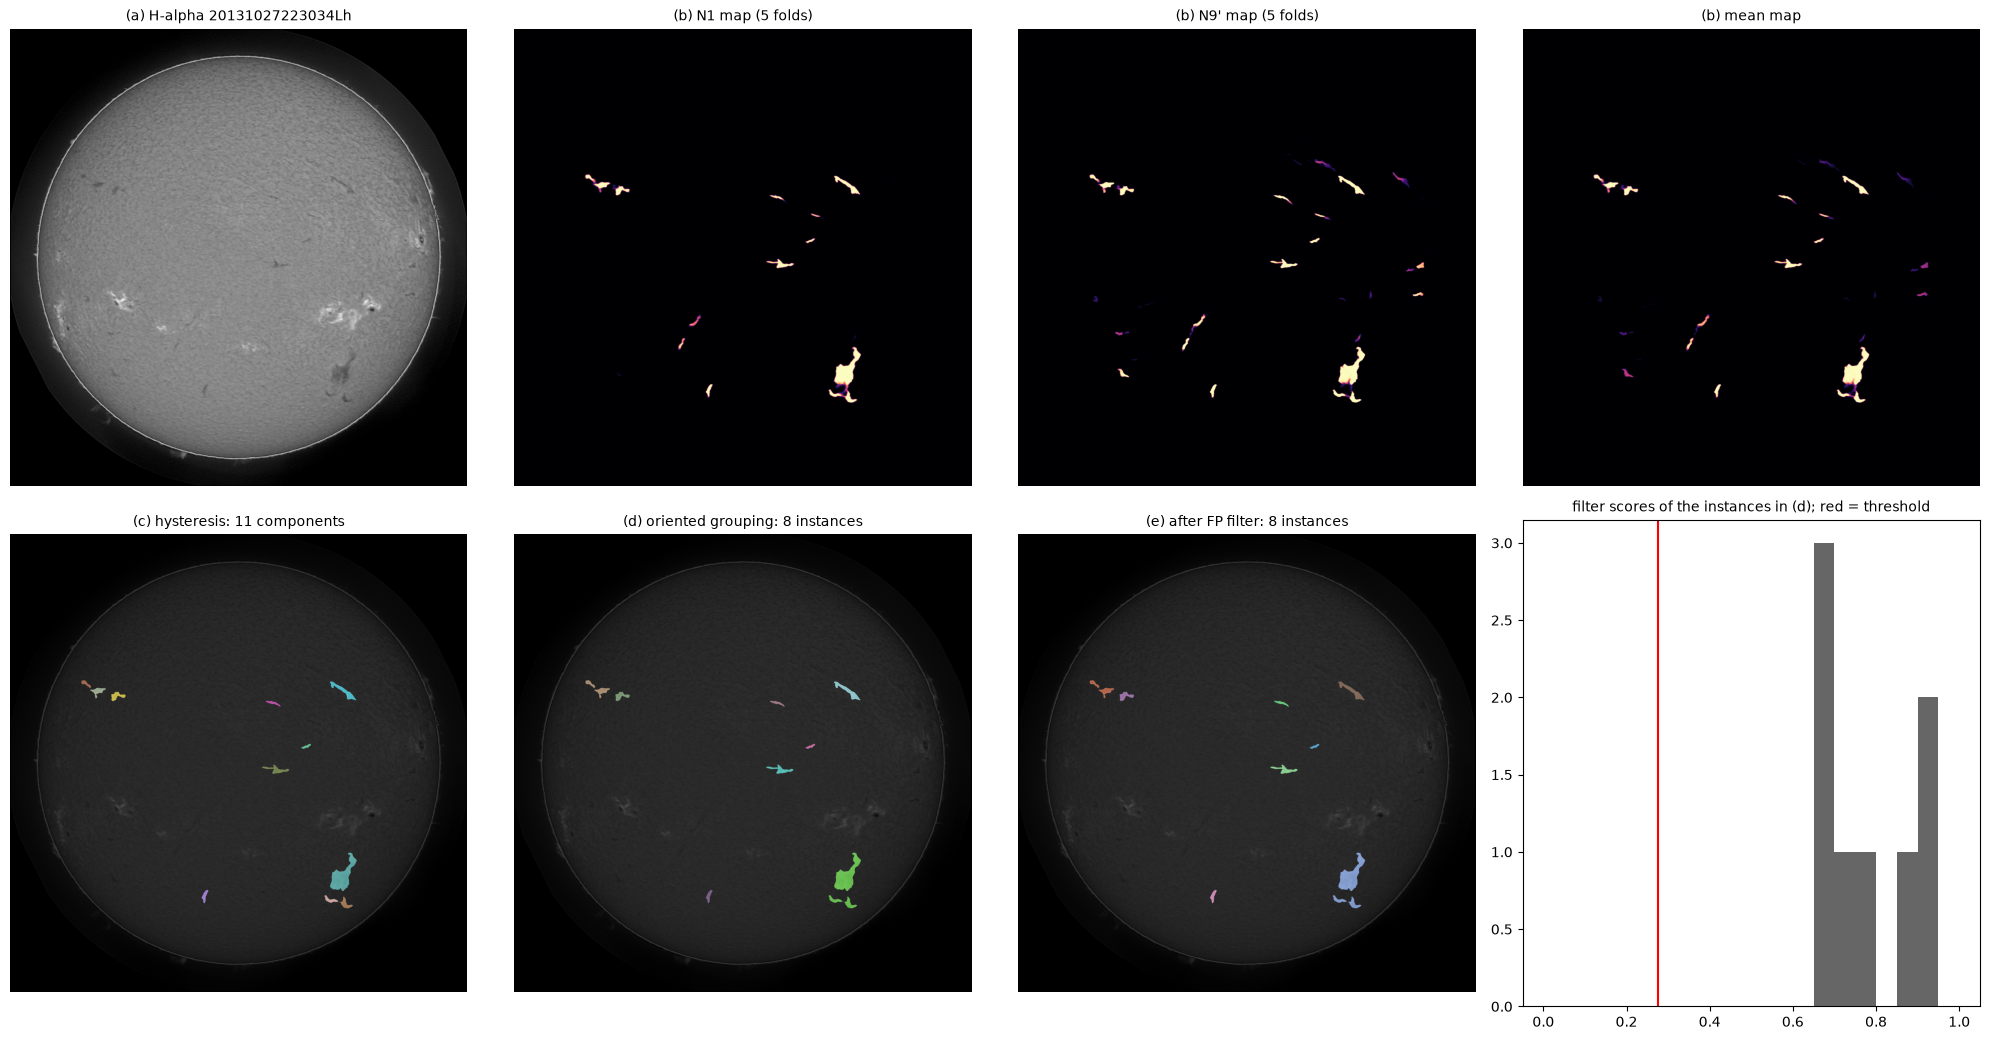

In [6]:
rng = np.random.default_rng(0)
def colour(lab):
    lut = np.vstack([[0, 0, 0], rng.uniform(0.25, 1, (int(lab.max()), 3))])
    return lut[lab]
def overlay(ax, gray, lab, title):
    ax.imshow(gray, cmap='gray')
    if lab is not None:
        ax.imshow(np.ma.masked_where(lab[..., None].repeat(3, 2) == 0, colour(lab)), alpha=0.7)
    ax.set_title(title, fontsize=10); ax.axis('off')

import cv2
res = prob.shape[0]
gray = cv2.resize(load_gray(paths[DEMO]), (res, res), interpolation=cv2.INTER_AREA)
fams = [load_maps(m / f, DEMO)[0] for f in ('n1', 'n9p')]
fig, axes = plt.subplots(2, 4, figsize=(20, 10.5))
overlay(axes[0, 0], gray, None, f'(a) H-alpha {DEMO}')
for ax, mp, t in zip(axes[0, 1:], fams + [prob], ['(b) N1 map (5 folds)', "(b) N9' map (5 folds)", '(b) mean map']):
    ax.imshow(cv2.resize(mp, (res, res)), cmap='magma', vmin=0, vmax=1); ax.set_title(t, fontsize=10); ax.axis('off')
overlay(axes[1, 0], gray, plain, f'(c) hysteresis: {plain.max()} components')
overlay(axes[1, 1], gray, grouped, f'(d) oriented grouping: {grouped.max()} instances')
overlay(axes[1, 2], gray, final, f'(e) after FP filter: {final.max()} instances')
axes[1, 3].hist(sc, bins=20, range=(0, 1), color='0.4'); axes[1, 3].axvline(filt['threshold'], color='r')
axes[1, 3].set_title('filter scores of the instances in (d); red = threshold', fontsize=10)
plt.tight_layout(); plt.show()

## 5. The submissions

final2: submission_final2.csv, 1038 filaments on 180 images, 5.8 per image (min 0, max 14), sha256 3e15afda22d03fcd
final1: submission_final1.csv, 987 filaments on 180 images, 5.5 per image (min 0, max 14), sha256 2a2337cf8aecf6bd
time: maps 0.0 min, ensembling + post-processing 37.8 min


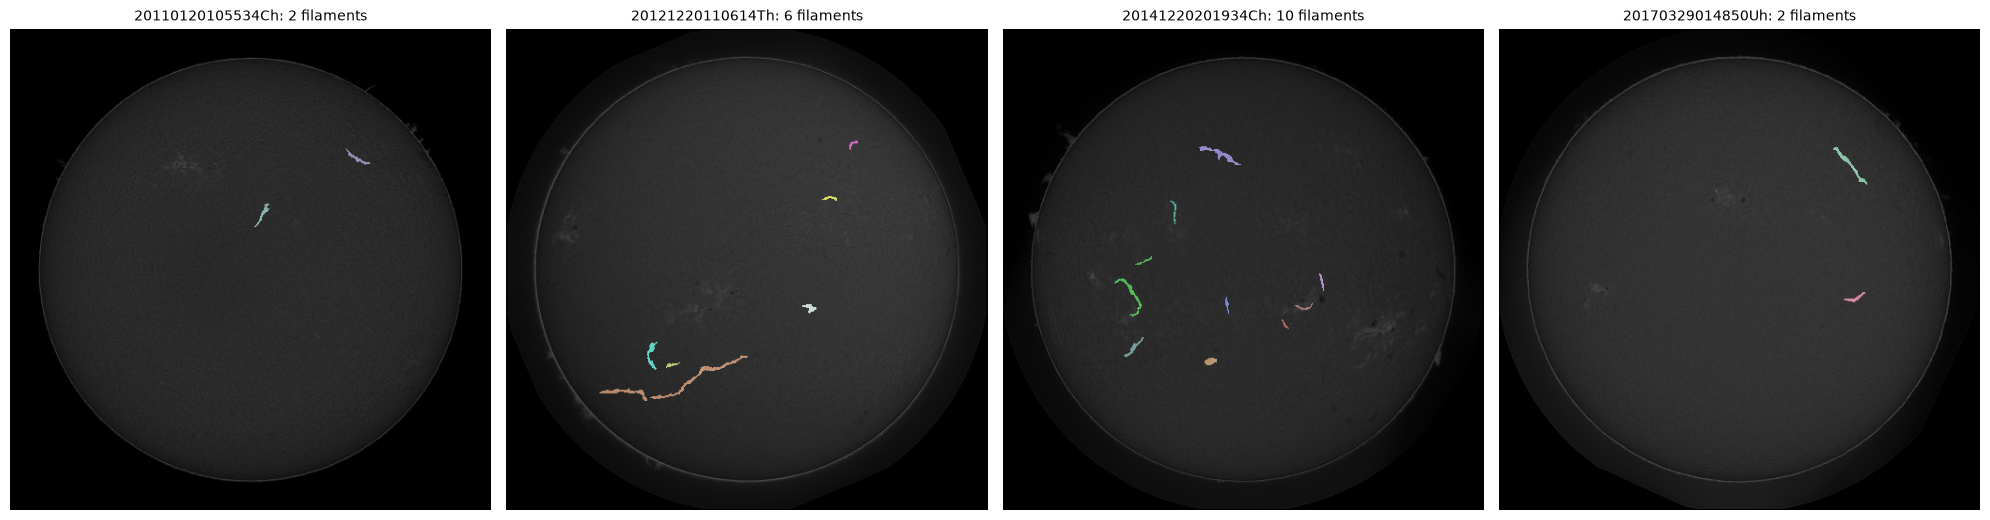

In [7]:
import pandas as pd
for name, f in SUBS.items():
    df = pd.read_csv(f)
    per_img = df.filament_id.str.rsplit('_', n=1).str[0].value_counts().reindex(sorted(paths), fill_value=0)
    print(f'{name}: {f.name}, {len(df)} filaments on {len(paths)} images, '
          f'{per_img.mean():.1f} per image (min {per_img.min()}, max {per_img.max()}), '
          f'sha256 {hashlib.sha256(f.read_bytes()).hexdigest()[:16]}')
print(f'time: maps {t_maps / 60:.1f} min, ensembling + post-processing {t_post / 60:.1f} min')

# four test images with the main submission's instances, decoded from the CSV itself
from pycocotools import mask as mask_util
main = pd.read_csv(next(iter(SUBS.values())))
main['stem'] = main.filament_id.str.rsplit('_', n=1).str[0]
show = sorted(paths)[::45][:4]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.3))
for ax, stem in zip(axes, show):
    lab = np.zeros((2048, 2048), np.int32)
    for k, r in enumerate(main[main.stem == stem].segmentation_rle, 1):
        lab[mask_util.decode({'size': [2048, 2048], 'counts': r}) > 0] = k
    small = cv2.resize(lab.astype(np.float32), (512, 512), interpolation=cv2.INTER_NEAREST).astype(np.int32)
    overlay(ax, cv2.resize(load_gray(paths[stem]), (512, 512), interpolation=cv2.INTER_AREA), small,
            f'{stem}: {lab.max()} filaments')
plt.tight_layout(); plt.show()

## 6. Hashes for the reproducibility check

In [8]:
# hashes for the reproducibility check, then drop the maps (several GB)
import hashlib, shutil
computed = [n for f in FAMILIES.values() for n in f] + list(FAMILIES) + [p for p in ('n1n9p', 'n1n2n9p') if (m / p).is_dir()]
dirs = ' '.join(f'{n}={m / n}' for n in computed)
run(f'{sys.executable} scripts/map_hashes.py --dirs {dirs} --out {OUT}/map_hashes.json')
for f in SUBS.values():
    print(f.name, hashlib.sha256(f.read_bytes()).hexdigest())
if ON_KAGGLE:
    shutil.copy(next(iter(SUBS.values())), OUT / 'submission.csv')
    shutil.rmtree(m)
    shutil.rmtree(REPO)

>> python scripts/map_hashes.py --dirs effb4_s1024_f0=outputs/final/maps/effb4_s1024_f0 effb4_s1024_f1=outputs/final/maps/effb4_s1024_f1 effb4_s1024_f2=outputs/final/maps/effb4_s1024_f2 effb4_s1024_f3=outputs/final/maps/effb4_s1024_f3 effb4_s1024_f4=outputs/final/maps/effb4_s1024_f4 effv2s_c512_f0=outputs/final/maps/effv2s_c512_f0 effv2s_c512_f1=outputs/final/maps/effv2s_c512_f1 effv2s_c512_f2=outputs/final/maps/effv2s_c512_f2 effv2s_c512_f3=outputs/final/maps/effv2s_c512_f3 effv2s_c512_f4=outputs/final/maps/effv2s_c512_f4 effb4_c2048_f0=outputs/final/maps/effb4_c2048_f0 effb4_c2048_f1=outputs/final/maps/effb4_c2048_f1 effb4_c2048_f2=outputs/final/maps/effb4_c2048_f2 effb4_c2048_f3=outputs/final/maps/effb4_c2048_f3 effb4_c2048_f4=outputs/final/maps/effb4_c2048_f4 n1=outputs/final/maps/n1 n9p=outputs/final/maps/n9p n2=outputs/final/maps/n2 n1n9p=outputs/final/maps/n1n9p n1n2n9p=outputs/final/maps/n1n2n9p --out outputs/final/map_hashes.json


effb4_s1024_f0: 180 maps
effb4_s1024_f1: 180 maps
effb4_s1024_f2: 180 maps
effb4_s1024_f3: 180 maps
effb4_s1024_f4: 180 maps
effv2s_c512_f0: 180 maps
effv2s_c512_f1: 180 maps
effv2s_c512_f2: 180 maps
effv2s_c512_f3: 180 maps
effv2s_c512_f4: 180 maps
effb4_c2048_f0: 180 maps
effb4_c2048_f1: 180 maps
effb4_c2048_f2: 180 maps
effb4_c2048_f3: 180 maps
effb4_c2048_f4: 180 maps
n1: 180 maps
n9p: 180 maps
n2: 180 maps
n1n9p: 180 maps
n1n2n9p: 180 maps
submission_final2.csv 3e15afda22d03fcd15fc021cbbbd26fe5cb83829420c3b0e02ab85a7b1dd424d
submission_final1.csv 2a2337cf8aecf6bd111faf3df13028db877bd33697bbac77747a73d4c3472dca
